<a href="https://colab.research.google.com/github/AmmarWarind/AmmarWarind/blob/main/deep_learning_project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
print("tensor flow version:",tf.__version__)
print("keras version:",keras.__version__)

tensor flow version: 2.21.0
keras version: 3.13.2


In [ ]:
tf.random.set_seed(42)
np.random.seed(42)


In [ ]:
(X_train,Y_train),(X_test,Y_test)=keras.datasets.mnist.load_data()
X_train.shape,Y_train.shape,X_test.shape,Y_test.shape

In [ ]:
Y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [ ]:
X_train

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [ ]:
Y_train[:10]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

In [ ]:
np.unique(Y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [ ]:
np.set_printoptions(linewidth=200)

print(X_train)

[[[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 ...

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]]


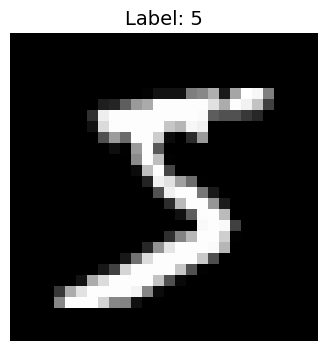

In [ ]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train[0], cmap='gray')
plt.title(f"Label: {Y_train[0]}", fontsize=14)
plt.axis('off')
plt.show()

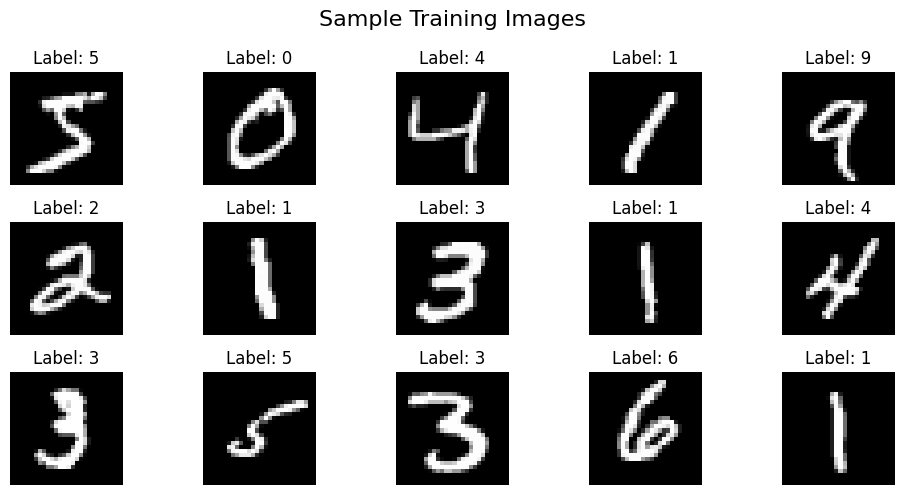

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)          # 3 rows, 5 columns, position i+1
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {Y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample Training Images", fontsize=16)
plt.tight_layout()
plt.show()

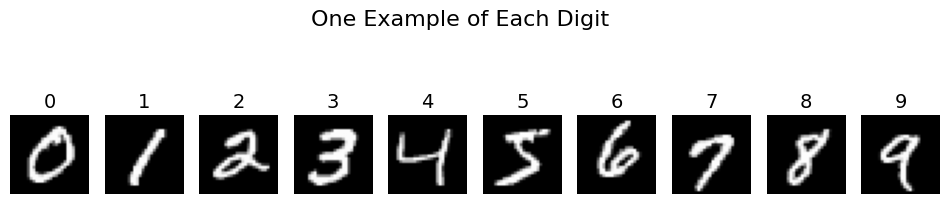

In [ ]:
plt.figure(figsize=(12, 3))

for digit in range(10):
    index = np.where(Y_train == digit)[0][0]   # first image of this digit
    plt.subplot(1, 10, digit + 1)
    plt.imshow(X_train[index], cmap='gray')
    plt.title(str(digit), fontsize=14)
    plt.axis('off')

plt.suptitle("One Example of Each Digit", fontsize=16)
plt.show()

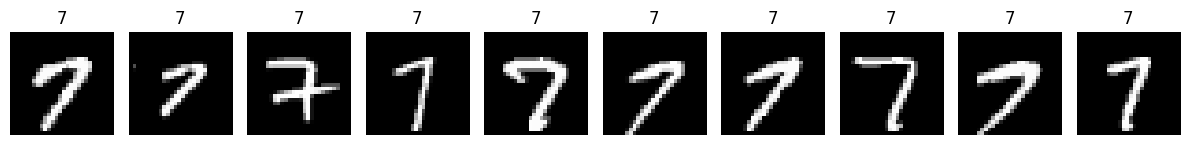

In [ ]:
digit_toshow = 7

indexes = np.where(Y_train == digit_toshow)[0][:10]

plt.figure(figsize=(12, 3))

for i, idx in enumerate(indexes):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[idx], cmap='gray')
    plt.title(str(digit_toshow))
    plt.axis('off')

plt.tight_layout()
plt.show()




In [ ]:
digits,counts=np.unique(Y_train,return_counts=True)
for d,c in zip(digits,counts):
  print(f"digit [d]:[c] images")

digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images
digit [d]:[c] images


/tmp/ipykernel_1977/2978355243.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=digits, y=counts, palette='viridis')


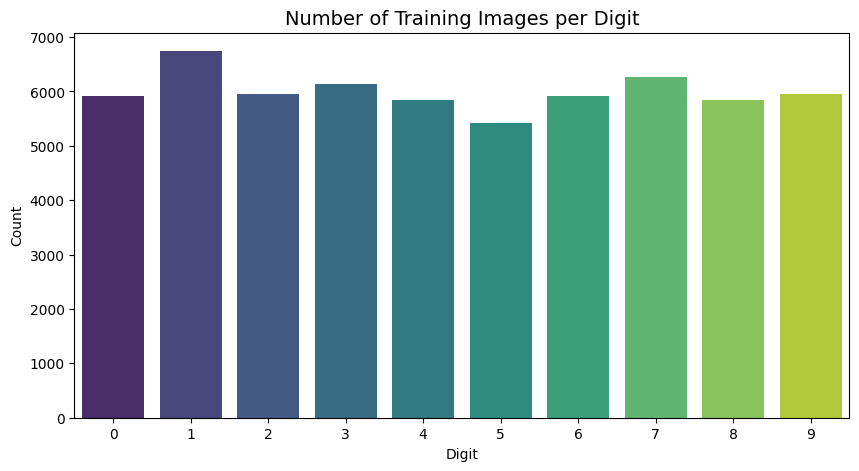

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x=digits, y=counts, palette='viridis')
plt.title("Number of Training Images per Digit", fontsize=14)
plt.xlabel("Digit")
plt.ylabel("Count")
plt.show()

In [ ]:
X_train=X_train/255.0
X_test=X_test/255.0

In [ ]:
print(X_train.min)
print(X_train.max)

In [ ]:

example_label = Y_train[0]
one_hot = keras.utils.to_categorical(example_label, num_classes=10)

print("Original label:", example_label)
print("One-hot label :", one_hot)

Original label: 5
One-hot label : [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [ ]:
flat_image=X_train[0].reshape(-1)
print(flat_image.shape)
print(X_train[0].shape)

(784,)
(28, 28)


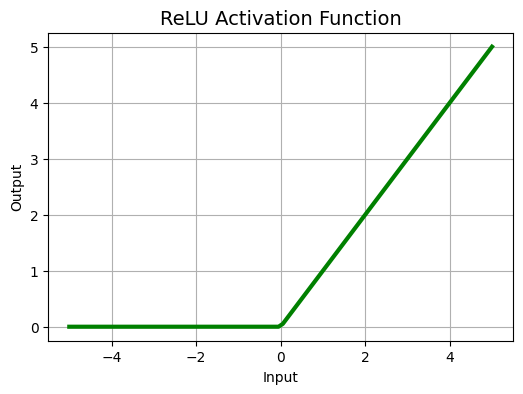

In [ ]:
x = np.linspace(-5, 5, 100)
relu = np.maximum(0, x)

plt.figure(figsize=(6, 4))
plt.plot(x, relu, linewidth=3, color='green')
plt.title("ReLU Activation Function", fontsize=14)
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)
plt.show()

In [ ]:
scores = np.array([1.0, 0.5, 0.2, 3.5, 0.1, 0.3, 0.0, 0.8, 0.4, 0.2])   # raw outputs
probabilities = np.exp(scores) / np.sum(np.exp(scores))

print("Probabilities:", np.round(probabilities, 3))
print("Sum of probabilities:", probabilities.sum())
print("Predicted digit:", np.argmax(probabilities))

Probabilities: [0.058 0.035 0.026 0.703 0.023 0.029 0.021 0.047 0.032 0.026]
Sum of probabilities: 1.0000000000000002
Predicted digit: 3


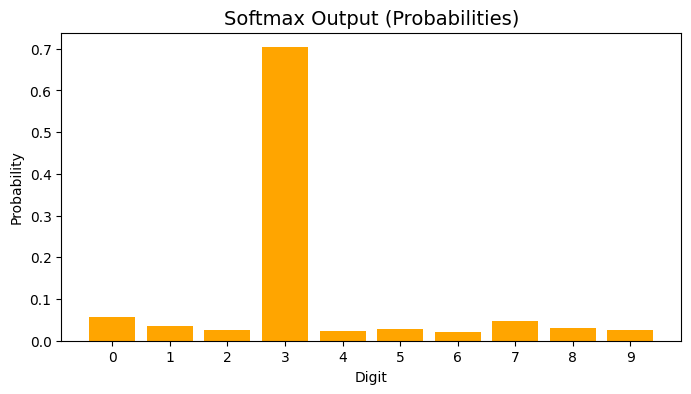

In [ ]:
plt.figure(figsize=(8, 4))
plt.bar(range(10), probabilities, color='orange')
plt.xticks(range(10))
plt.title("Softmax Output (Probabilities)", fontsize=14)
plt.xlabel("Digit")
plt.ylabel("Probability")
plt.show()

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [ ]:
55model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
print("model compiled succesfully")

model compiled succesfully


In [ ]:
Epochs=10
BATCH_SIZE=32

In [ ]:
history=model.fit(
    X_train,Y_train,
    epochs=Epochs,
    batch_size=BATCH_SIZE,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9849 - loss: 0.0458 - val_accuracy: 0.9807 - val_loss: 0.0826
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9851 - loss: 0.0439 - val_accuracy: 0.9798 - val_loss: 0.0808
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9865 - loss: 0.0404 - val_accuracy: 0.9802 - val_loss: 0.0764
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9865 - loss: 0.0397 - val_accuracy: 0.9810 - val_loss: 0.0874
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9873 - loss: 0.0386 - val_accuracy: 0.9835 - val_loss: 0.0728
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9876 - loss: 0.0365 - val_accuracy: 0.9803 - val_loss: 0.0799
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9884 - loss: 0.0355 - val_accuracy: 0.9827 - val_loss: 0.0719
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9885 - loss: 0.0315 - 

In [ ]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


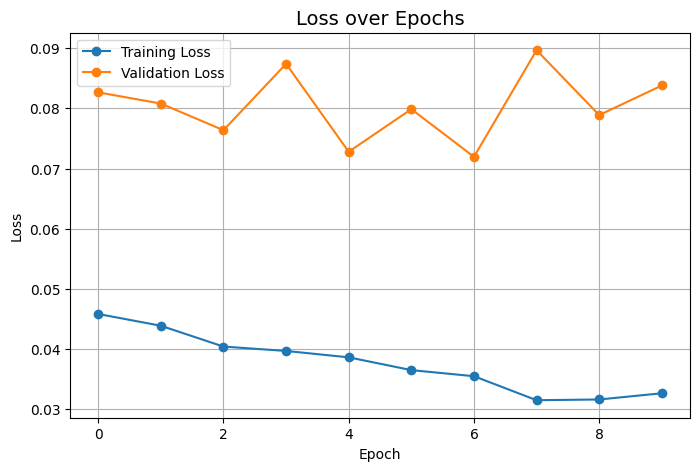

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title("Loss over Epochs", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss,test_accuracy=model.evaluate(X_test,Y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9796 - loss: 0.0868
Test Loss: 0.0868
Test Accuracy: 97.96%


In [ ]:
predictions=model.predict(X_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [ ]:
predictions.shape

(10000, 10)

In [ ]:
print(np.round(predictions[0], 3))

[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [ ]:
predicted_label = np.argmax(predictions[0])
print("Predicted digit:", predicted_label)
print("Actual digit   :", Y_test[0])

Predicted digit: 7
Actual digit   : 7


In [ ]:
y_pred = np.argmax(predictions, axis=1)
print("First 20 predictions:", y_pred[:20])
print("First 20 actual     :", Y_test[:20])

First 20 predictions: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 8 4]
First 20 actual     : [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [ ]:
index = 0

plt.figure(figsize=(10, 4))

# Left: the image
plt.subplot(1, 2, 1)
plt.imshow(X_test[index], cmap='gray')
plt.title(f"Actual: {y_test[index]}  |  Predicted: {y_pred[index]}", fontsize=12)
plt.axis('off')

# Right: the probabilities
plt.subplot(1, 2, 2)
plt.bar(range(10), predictions[index], color='skyblue')
plt.xticks(range(10))
plt.title("Model Confidence for Each Digit", fontsize=12)
plt.xlabel("Digit")
plt.ylabel("Probability")

plt.tight_layout()
plt.show()

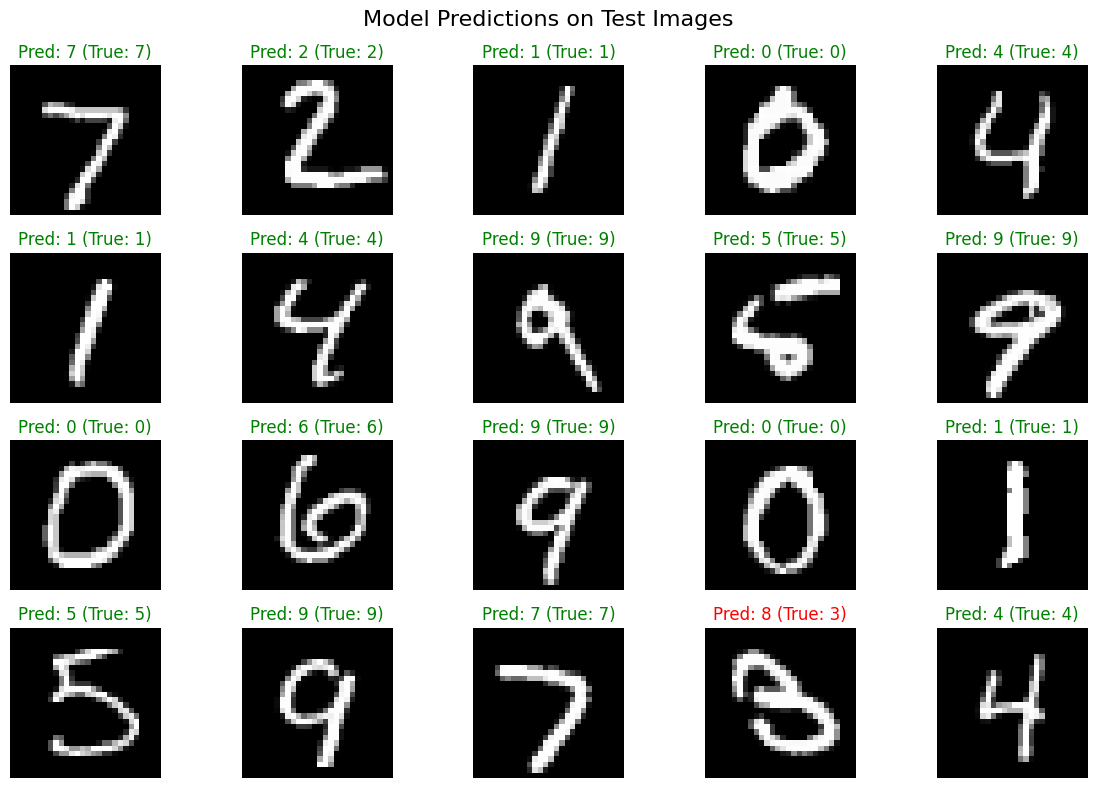

In [ ]:
plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')

    color = 'green' if y_pred[i] == Y_test[i] else 'red'
    plt.title(f"Pred: {y_pred[i]} (True: {Y_test[i]})", color=color)
    plt.axis('off')

plt.suptitle("Model Predictions on Test Images", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files
from PIL import Image,ImageOps


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving no 3.png to no 3.png


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open('no 3.png').convert('L')

img = img.resize((28, 28))

img_array = np.array(img)

# Normalize
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

print("Input shape:", img_array.shape)

In [ ]:
prediction = model.predict(img_array)

predicted_digit = np.argmax(prediction)

confidence = np.max(prediction) * 100

print("Predicted Digit:", predicted_digit)
print("Confidence:", confidence, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Predicted Digit: 3
Confidence: 61.550407 %


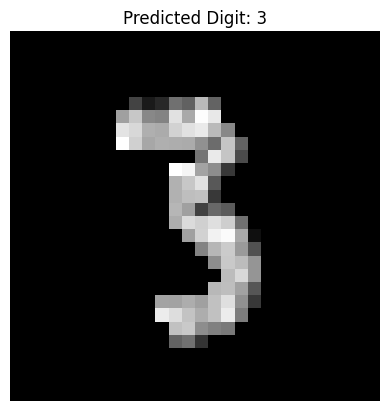

In [ ]:
plt.imshow(img_array[0], cmap='gray')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis('off')
plt.show()